In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from skimage import io, measure

In [3]:
vehicle_nupr1 = io.imread('Vehicle_NUPR1_Cy3.tif')
fisetin_nupr1 = io.imread('Fisetin_NUPR1_Cy3.tif')

vehicle_mask = io.imread('Vehicle_DAPI_Mask.tif')
fisetin_mask = io.imread('Fisetin_DAPI_Mask.tif')

In [4]:
print(vehicle_nupr1.shape, vehicle_nupr1.dtype)
print(fisetin_nupr1.shape, fisetin_nupr1.dtype)

print(vehicle_mask.shape, vehicle_mask.dtype)
print(fisetin_mask.shape, fisetin_mask.dtype)

(3008, 4096) uint16
(3008, 4096) uint16
(3008, 4096) uint8
(3008, 4096) uint8


In [5]:
print(np.unique(vehicle_mask))
print(np.unique(fisetin_mask))

[  0 255]
[  0 255]


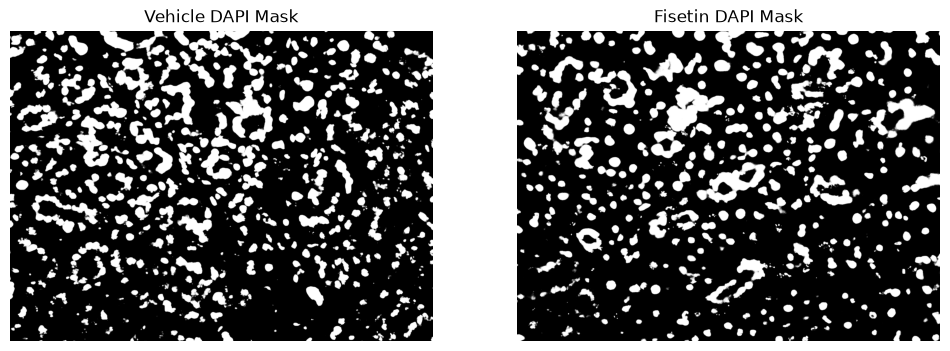

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(vehicle_mask, cmap='gray')
ax[0].set_title('Vehicle DAPI Mask')
ax[0].axis('off')

ax[1].imshow(fisetin_mask, cmap='gray')
ax[1].set_title('Fisetin DAPI Mask')
ax[1].axis('off')

plt.show()

In [8]:
from scipy import ndimage as ndi
from skimage.segmentation import watershed
from skimage.feature import peak_local_max

In [10]:
def segment_nuclei(mask):
    binary = mask > 0
    distance = ndi.distance_transform_edt(binary)

    coords = peak_local_max(distance, min_distance=20,
                            labels=binary)

    markers = np.zeros(binary.shape, dtype=bool)
    markers[tuple(coords.T)] = True
    markers = ndi.label(markers)[0]

    labels = watershed(-distance, markers, mask=binary)

    return labels

In [11]:
vehicle_labels = segment_nuclei(vehicle_mask)
fisetin_labels = segment_nuclei(fisetin_mask)

print("Vehicle regions:", vehicle_labels.max())
print("Fisetin regions:", fisetin_labels.max())

Vehicle regions: 943
Fisetin regions: 723


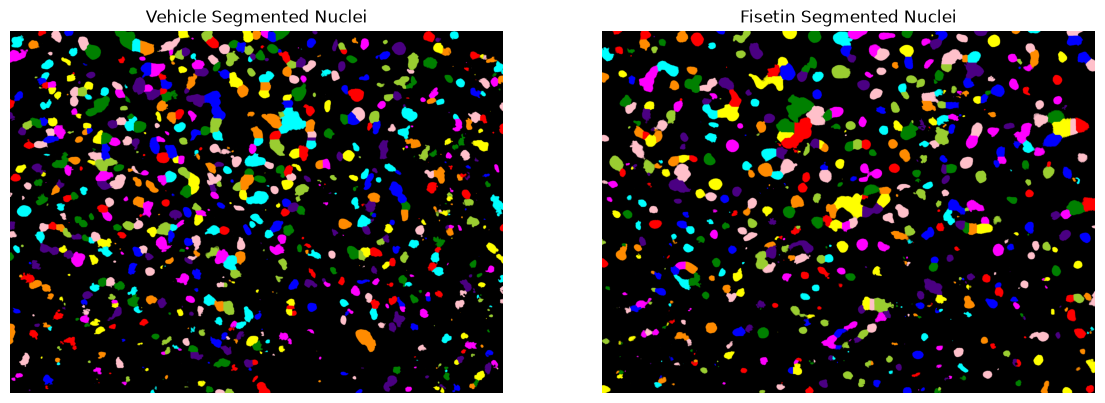

In [12]:
from skimage.color import label2rgb

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(label2rgb(vehicle_labels, bg_label=0))
ax[0].set_title('Vehicle Segmented Nuclei')
ax[0].axis('off')

ax[1].imshow(label2rgb(fisetin_labels, bg_label=0))
ax[1].set_title('Fisetin Segmented Nuclei')
ax[1].axis('off')

plt.show()

In [13]:
vehicle_props = measure.regionprops_table(
    vehicle_labels,
    intensity_image=vehicle_nupr1,
    properties=('label', 'area', 'mean_intensity')
)

fisetin_props = measure.regionprops_table(
    fisetin_labels,
    intensity_image=fisetin_nupr1,
    properties=('label', 'area', 'mean_intensity')
)

vehicle_df = pd.DataFrame(vehicle_props)
fisetin_df = pd.DataFrame(fisetin_props)

vehicle_df.head()

,label,area,mean_intensity
0,1,2186.0,2848.657365
1,2,2812.0,2724.378378
2,3,4785.0,2646.084222
3,4,3134.0,2763.001914
4,5,6996.0,3158.024300


In [14]:
print("Vehicle nuclear areas:")
print(vehicle_df['area'].describe())

print("Fisetin nuclear areas:")
print(fisetin_df['area'].describe())

Vehicle nuclear areas:
count      943.000000
mean      2906.291622
std       2954.899494
min          1.000000
25%        415.500000
50%       2314.000000
75%       4530.500000
max      30311.000000
Name: area, dtype: float64
Fisetin nuclear areas:
count      723.000000
mean      3424.040111
std       3694.676300
min          1.000000
25%        458.500000
50%       2780.000000
75%       5037.500000
max      31203.000000
Name: area, dtype: float64


In [15]:
vehicle_filtered = vehicle_df[
    (vehicle_df['area'] >= 500) &
    (vehicle_df['area'] <= 10000)
].copy()

fisetin_filtered = fisetin_df[
    (fisetin_df['area'] >= 500) &
    (fisetin_df['area'] <= 10000)
].copy()

print("Vehicle remaining regions:", len(vehicle_filtered))
print("Fisetin remaining regions:", len(fisetin_filtered))

Vehicle remaining regions: 672
Fisetin remaining regions: 507


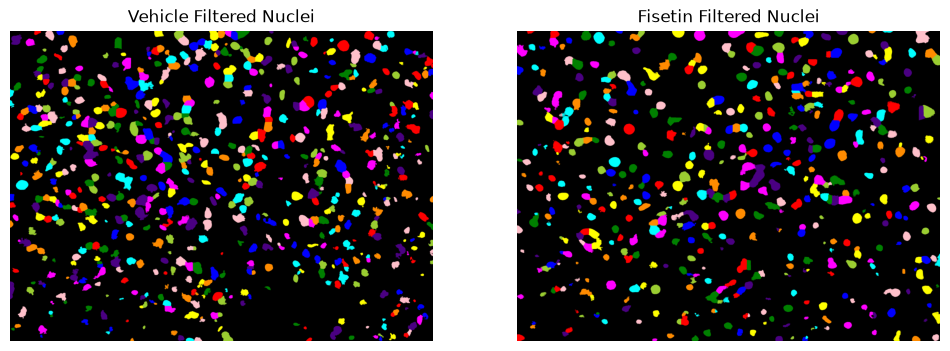

In [16]:
vehicle_clean = np.where(
    np.isin(vehicle_labels, vehicle_filtered['label']),
    vehicle_labels, 0
)

fisetin_clean = np.where(
    np.isin(fisetin_labels, fisetin_filtered['label']),
    fisetin_labels, 0
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(label2rgb(vehicle_clean, bg_label=0))
ax[0].set_title('Vehicle Filtered Nuclei')
ax[0].axis('off')

ax[1].imshow(label2rgb(fisetin_clean, bg_label=0))
ax[1].set_title('Fisetin Filtered Nuclei')
ax[1].axis('off')

plt.show()

In [17]:
print("Vehicle NUPR1 intensity:")
print(vehicle_filtered['mean_intensity'].describe())

print("Fisetin NUPR1 intensity:")
print(fisetin_filtered['mean_intensity'].describe())

Vehicle NUPR1 intensity:
count     672.000000
mean     2830.351297
std       437.498564
min      2103.066077
25%      2580.596286
50%      2759.905505
75%      2959.417678
max      7811.382385
Name: mean_intensity, dtype: float64
Fisetin NUPR1 intensity:
count     507.000000
mean     2667.797906
std       279.314858
min      2190.699041
25%      2465.402680
50%      2611.534617
75%      2822.322006
max      4141.629136
Name: mean_intensity, dtype: float64


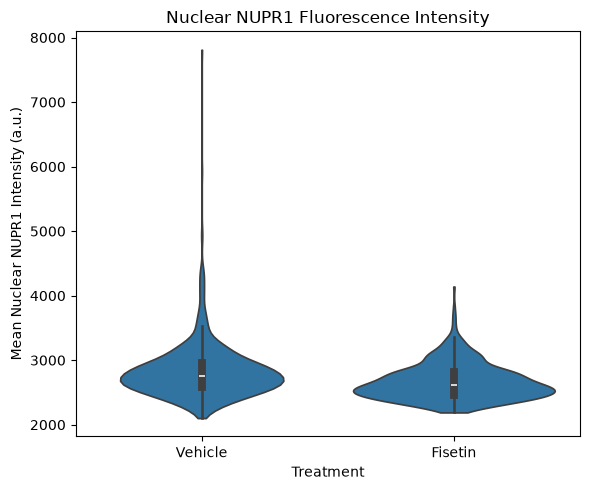

In [20]:
vehicle_filtered['Treatment'] = 'Vehicle'
fisetin_filtered['Treatment'] = 'Fisetin'

combined_df = pd.concat(
    [vehicle_filtered, fisetin_filtered],
    ignore_index=True
)

fig, ax = plt.subplots(1, 1, figsize=(6, 5))

sns.violinplot(
    data=combined_df,
    x='Treatment',
    y='mean_intensity',
    ax=ax,
    cut=0
)

ax.set_ylabel('Mean Nuclear NUPR1 Intensity (a.u.)')
ax.set_xlabel('Treatment')
ax.set_title('Nuclear NUPR1 Fluorescence Intensity')

plt.tight_layout()
plt.savefig('NUPR1_Violin_Plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
summary = combined_df.groupby('Treatment')['mean_intensity'].agg(['mean', 'std'])

summary = summary.reindex(['Vehicle', 'Fisetin'])

summary

,mean,std
Treatment,,
Vehicle,2830.351297,437.498564
Fisetin,2667.797906,279.314858


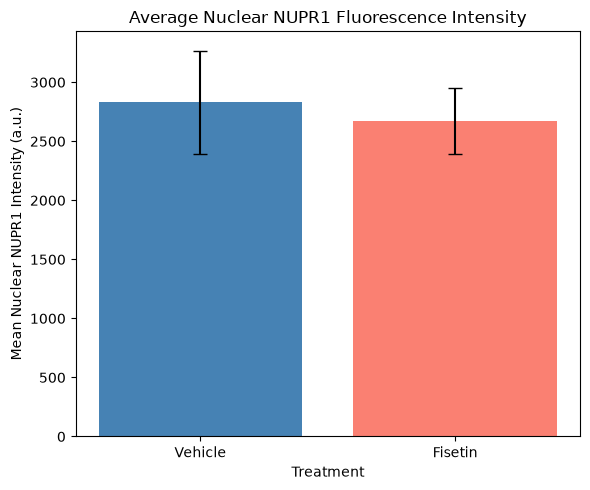

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.bar(
    summary.index,
    summary['mean'],
    yerr=summary['std'],
    capsize=5,
    color=['steelblue', 'salmon']
)

ax.set_xlabel('Treatment')
ax.set_ylabel('Mean Nuclear NUPR1 Intensity (a.u.)')
ax.set_title('Average Nuclear NUPR1 Fluorescence Intensity')

plt.tight_layout()
plt.savefig('NUPR1_Bar_Graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
combined_df.to_csv('NUPR1_Nuclear_Intensity_Data.csv', index=False)

summary.to_csv('NUPR1_Summary_Statistics.csv')